# Where the magnitude correlation peaks

This notebook reads the five saved latent pairs in `results/geometric_registration/latent_undo_n5`. It does not generate images or run diffusion.

Each inverted latent `z_hat` came from an image that had been shifted or rotated by a known amount. Here that latent is corrected by many hypothesized amounts, not only the true one. The score at each hypothesis is `pearsonr(|z|, |corrected latent|)`, the same absolute-value correlation as the registration run. The curves are the mean over the five images. The star sits at the true image perturbation.

A hypothesized shift of `n` pixels moves the latent by `n/8` pixels in the opposite direction, with linear interpolation. A hypothesized rotation of `n` degrees rotates each latent channel by `n` degrees in the opposite direction, with a cubic spline. Vacated sites are filled with 0. Linear interpolation is used for shifts because nearest-neighbor latent shifts are constant across several image pixels, so a finer pixel axis would otherwise repeat the same score. Candidate 0 leaves the inverted latent unchanged.


## 1. Load the five samples


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy import ndimage
from scipy.stats import pearsonr

RUN_DIR = Path("results/geometric_registration/latent_undo_n5")
LATENT_DIR = RUN_DIR / "latents"
if not LATENT_DIR.is_dir():
    raise SystemExit(f"Missing {LATENT_DIR}. Copy the HiPerGator latent_undo_n5 directory here first.")

meta = json.loads((RUN_DIR / "metadata.json").read_text(encoding="utf-8"))
VAE_SCALE_FACTOR = int(meta["vae_scale_factor"])
CONDITIONS = [(row["transformation_type"], float(row["magnitude"])) for row in meta["conditions"]]
FAMILIES = ["horizontal_translation", "vertical_translation", "rotation"]
FAMILY_TITLES = {
    "horizontal_translation": "hypothesized horizontal undo (pixels)",
    "vertical_translation": "hypothesized vertical undo (pixels)",
    "rotation": "hypothesized rotation undo (degrees)",
}
TRUE_MAGNITUDES = [0.0, 1.0, 2.0, 5.0, 10.0]
CANDIDATES = np.round(np.arange(0.0, 12.0 + 1e-9, 0.5), 1)
for magnitude in TRUE_MAGNITUDES:
    if magnitude not in set(CANDIDATES):
        raise SystemExit(f"true magnitude {magnitude} is not on the candidate grid")

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

blobs = []
for sample_id in range(int(meta["num_samples"])):
    path = LATENT_DIR / f"sample_{sample_id:03d}.pt"
    if not path.is_file():
        raise SystemExit(f"missing {path}")
    blobs.append(torch.load(path, map_location="cpu", weights_only=True))
print(f"loaded {len(blobs)} samples, {len(CANDIDATES)} candidate corrections per curve")
print(f"true perturbations: {TRUE_MAGNITUDES}")


loaded 5 samples, 25 candidate corrections per curve
true perturbations: [0.0, 1.0, 2.0, 5.0, 10.0]


## 2. Score every hypothesized correction

For a horizontal or vertical condition, the image content was moved right or down. The correction moves the latent left or up. For a rotation, the image was turned counterclockwise and the correction turns the latent clockwise. The baseline latent is included as a true perturbation of 0, and the same family of corrections is applied to it.


In [2]:
def latent_key(kind: str, magnitude: float) -> str:
    return f"z_hat__{kind}__{magnitude:.1f}"


def correct_latent(latent: np.ndarray, kind: str, candidate: float) -> np.ndarray:
    spatial = np.asarray(latent, dtype=np.float32)
    if spatial.ndim == 4:
        spatial = spatial[0]
    if candidate == 0:
        return spatial.copy()
    if kind == "horizontal_translation":
        shift = (0.0, -candidate / VAE_SCALE_FACTOR)
        order = 1
        moved = [ndimage.shift(channel, shift=shift, order=order, mode="constant", cval=0.0) for channel in spatial]
    elif kind == "vertical_translation":
        shift = (-candidate / VAE_SCALE_FACTOR, 0.0)
        moved = [ndimage.shift(channel, shift=shift, order=1, mode="constant", cval=0.0) for channel in spatial]
    elif kind == "rotation":
        moved = [
            ndimage.rotate(channel, angle=-candidate, reshape=False, order=3, mode="constant", cval=0.0, prefilter=True)
            for channel in spatial
        ]
    else:
        raise ValueError(kind)
    return np.stack(moved, axis=0).astype(np.float32)


def magnitude_correlation(z: np.ndarray, other: np.ndarray) -> float:
    left = np.abs(np.asarray(z, dtype=np.float64)).ravel()
    right = np.abs(np.asarray(other, dtype=np.float64)).ravel()
    result = pearsonr(left, right)
    return float(result.statistic)


rows = []
for sample_id, blob in enumerate(blobs):
    z = blob["z"].numpy()
    for kind in FAMILIES:
        for true_magnitude in TRUE_MAGNITUDES:
            source_kind = "baseline" if true_magnitude == 0 else kind
            z_hat = blob[latent_key(source_kind, true_magnitude)].numpy()
            for candidate in CANDIDATES:
                corrected = correct_latent(z_hat, kind, float(candidate))
                rows.append({
                    "sample_id": sample_id,
                    "transformation_type": kind,
                    "true_magnitude": true_magnitude,
                    "candidate": float(candidate),
                    "correlation": magnitude_correlation(z, corrected),
                })
    print(f"scored sample {sample_id + 1}/{len(blobs)}", flush=True)

scores = pd.DataFrame(rows)
if not np.isfinite(scores.correlation).all():
    raise SystemExit("a correlation is non-finite")
print(f"rows {len(scores)}")


scored sample 1/5


scored sample 2/5


scored sample 3/5


scored sample 4/5


scored sample 5/5


rows 1875


## 3. Correlation against the hypothesized perturbation

Each line is one true image perturbation. The star marks that true amount on its own line. A peak on the star means the absolute-value correlation is highest when the latent is corrected by the perturbation that was actually applied.


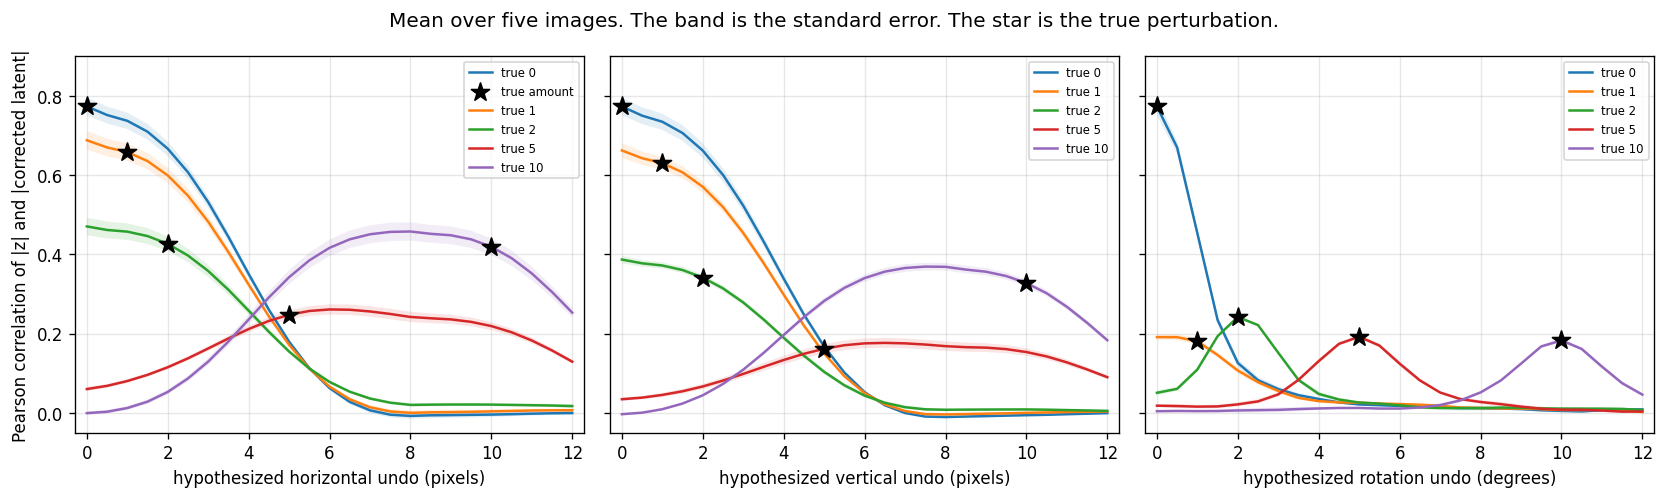

In [3]:
mean_scores = (
    scores.groupby(["transformation_type", "true_magnitude", "candidate"])["correlation"]
    .agg(mean="mean", std="std", count="count")
    .reset_index()
)
mean_scores["sem"] = mean_scores["std"] / np.sqrt(mean_scores["count"])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
marked = False
for ax, kind in zip(axes, FAMILIES):
    block = mean_scores.loc[mean_scores.transformation_type == kind]
    for true_magnitude in TRUE_MAGNITUDES:
        curve = block.loc[block.true_magnitude == true_magnitude].sort_values("candidate")
        label = f"true {true_magnitude:g}"
        ax.plot(curve.candidate, curve["mean"], label=label)
        ax.fill_between(curve.candidate, curve["mean"] - curve["sem"], curve["mean"] + curve["sem"], alpha=0.12)
        at_true = curve.loc[np.isclose(curve.candidate, true_magnitude)].iloc[0]
        ax.scatter(
            [true_magnitude],
            [at_true["mean"]],
            marker="*",
            s=130,
            color="black",
            zorder=5,
            label="true amount" if not marked else None,
        )
        marked = True
    ax.set(xlabel=FAMILY_TITLES[kind], xlim=(-0.3, 12.3), ylim=(-0.05, 0.9))
    ax.legend(fontsize=7, loc="best")
axes[0].set_ylabel("Pearson correlation of |z| and |corrected latent|")
fig.suptitle("Mean over five images. The band is the standard error. The star is the true perturbation.")
fig.tight_layout()
plt.show()


## 4. Does the curve peak at the true amount?

The peak is the candidate with the highest mean correlation. If several candidates tie, the one closest to the true perturbation is kept. The sample count is how many of the five images have their own peak at that same true amount.


In [4]:
def peak_of(candidates: np.ndarray, values: np.ndarray, true_magnitude: float) -> float:
    best = np.max(values)
    tied = candidates[np.isclose(values, best)]
    return float(tied[np.argmin(np.abs(tied - true_magnitude))])


sample_peak_rows = []
for (sample_id, kind, true_magnitude), group in scores.groupby(
    ["sample_id", "transformation_type", "true_magnitude"]
):
    sample_peak_rows.append({
        "sample_id": sample_id,
        "transformation_type": kind,
        "true_magnitude": float(true_magnitude),
        "sample_peak": peak_of(group.candidate.to_numpy(), group.correlation.to_numpy(), float(true_magnitude)),
    })
sample_peaks = pd.DataFrame(sample_peak_rows)

lines = []
for kind in FAMILIES:
    for true_magnitude in TRUE_MAGNITUDES:
        curve = mean_scores.loc[
            (mean_scores.transformation_type == kind) & np.isclose(mean_scores.true_magnitude, true_magnitude)
        ]
        peak = peak_of(curve.candidate.to_numpy(), curve["mean"].to_numpy(), true_magnitude)
        best = float(curve["mean"].max())
        at_true = float(curve.loc[np.isclose(curve.candidate, true_magnitude), "mean"].iloc[0])
        at_zero = float(curve.loc[np.isclose(curve.candidate, 0.0), "mean"].iloc[0])
        sample_peak = sample_peaks.loc[
            (sample_peaks.transformation_type == kind) & np.isclose(sample_peaks.true_magnitude, true_magnitude),
            "sample_peak",
        ]
        hits = int(np.isclose(sample_peak.to_numpy(), true_magnitude).sum())
        lines.append({
            "transformation_type": kind,
            "true_magnitude": true_magnitude,
            "peak_candidate": peak,
            "correlation_at_peak": best,
            "correlation_at_true": at_true,
            "correlation_at_0": at_zero,
            "samples_peaking_at_true": hits,
        })
        print(
            f"{kind} true {true_magnitude:g}: mean peaks at {peak:g} "
            f"(corr {best:.3f}; at the true amount {at_true:.3f}; at 0 {at_zero:.3f}); "
            f"{hits}/{len(sample_peak)} images peak at the true amount"
        )

pd.DataFrame(lines).round(3)


horizontal_translation true 0: mean peaks at 0 (corr 0.773; at the true amount 0.773; at 0 0.773); 5/5 images peak at the true amount
horizontal_translation true 1: mean peaks at 0 (corr 0.687; at the true amount 0.658; at 0 0.687); 0/5 images peak at the true amount
horizontal_translation true 2: mean peaks at 0 (corr 0.470; at the true amount 0.426; at 0 0.470); 0/5 images peak at the true amount
horizontal_translation true 5: mean peaks at 6 (corr 0.261; at the true amount 0.247; at 0 0.060); 0/5 images peak at the true amount
horizontal_translation true 10: mean peaks at 8 (corr 0.457; at the true amount 0.419; at 0 -0.001); 0/5 images peak at the true amount
vertical_translation true 0: mean peaks at 0 (corr 0.773; at the true amount 0.773; at 0 0.773); 5/5 images peak at the true amount
vertical_translation true 1: mean peaks at 0 (corr 0.662; at the true amount 0.630; at 0 0.662); 0/5 images peak at the true amount
vertical_translation true 2: mean peaks at 0 (corr 0.387; at the

,transformation_type,true_magnitude,peak_candidate,correlation_at_peak,correlation_at_true,correlation_at_0,samples_peaking_at_true
0,horizontal_translation,0.0,0.0,0.773,0.773,0.773,5
1,horizontal_translation,1.0,0.0,0.687,0.658,0.687,0
2,horizontal_translation,2.0,0.0,0.470,0.426,0.470,0
3,horizontal_translation,5.0,6.0,0.261,0.247,0.060,0
4,horizontal_translation,10.0,8.0,0.457,0.419,-0.001,0
5,vertical_translation,0.0,0.0,0.773,0.773,0.773,5
6,vertical_translation,1.0,0.0,0.662,0.630,0.662,0
7,vertical_translation,2.0,0.0,0.387,0.341,0.387,0
8,vertical_translation,5.0,6.5,0.176,0.162,0.034,0
9,vertical_translation,10.0,7.5,0.369,0.327,-0.003,0
